# Tujuan Analisis Data

Menganalisis pola telemetri konsumsi kafein untuk mengidentifikasi korelasi antara variabel kebiasaan konsumsi (dosis, sumber, gula, durasi), faktor biometrik/genetik (tipe metabolisme CYP1A2, toleransi, durasi tidur, hidrasi), dan respons tubuh akut guna memprediksi tingkat risiko crash serta kecemasan (anxiety).

# Data Understanding & Preprocessing

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

In [11]:
df = pd.read_csv("caffeine_crash_and_anxiety_telemetry.csv")
display(df.head())

,user_id,age,gender,cyp1a2_metabolizer_type,caffeine_tolerance,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,primary_caffeine_source,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,jitters_intensity_score,acute_anxiety_score,crash_onset_hours,crash_severity_score,crash_risk_level
0,CAF-00001,27,Female,Fast,High,2.4,7.0,2.29,Brewed Drip Coffee,138,8.7,36,2.0,1.0,1.0,7.5,4.1,Mild Afternoon Fatigue
1,CAF-00002,57,Female,Fast,Low,9.1,7.1,2.41,Energy Drink (Sugar-Free),164,0.0,3,2.4,2.0,5.5,7.5,2.5,Sustained / Negligible Crash
2,CAF-00003,39,Male,Normal,Low,2.9,5.1,2.07,Energy Drink (Full Sugar),179,36.9,10,3.8,4.8,5.5,3.6,7.9,Moderate Crash & Lethargy
3,CAF-00004,34,Female,Fast,Moderate,3.8,5.0,2.34,Pre-Workout Supplement,408,1.6,3,6.8,4.2,7.3,7.5,10.0,Severe Crash & Tachycardia
4,CAF-00005,22,Female,Slow,High,2.0,6.3,1.92,Energy Drink (Full Sugar),170,50.2,11,2.0,2.0,1.1,2.6,10.0,Severe Crash & Tachycardia


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8000 non-null   object 
 1   age                       8000 non-null   int64  
 2   gender                    8000 non-null   object 
 3   cyp1a2_metabolizer_type   8000 non-null   object 
 4   caffeine_tolerance        8000 non-null   object 
 5   baseline_anxiety_score    8000 non-null   float64
 6   prior_sleep_hours         8000 non-null   float64
 7   daily_hydration_liters    8000 non-null   float64
 8   primary_caffeine_source   8000 non-null   object 
 9   caffeine_mg               8000 non-null   int64  
 10  sugar_grams               8000 non-null   float64
 11  consumption_duration_min  8000 non-null   int64  
 12  heart_rate_spike_bpm      8000 non-null   float64
 13  jitters_intensity_score   8000 non-null   float64
 14  acute_an

In [8]:
df.describe()

,age,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,jitters_intensity_score,acute_anxiety_score,crash_onset_hours,crash_severity_score
count,8000.000000,8000.00000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,32.950875,3.48855,6.375550,2.108222,198.044125,18.026025,28.976250,4.669675,3.323437,3.683588,5.648900,6.294100
std,11.513711,2.07950,1.292857,0.783542,65.865873,19.132112,20.488751,4.004456,2.310030,2.370665,1.394713,2.334954
min,18.000000,1.00000,3.200000,0.600000,40.000000,0.000000,3.000000,2.000000,1.000000,1.000000,1.500000,1.000000
25%,24.000000,1.80000,5.500000,1.560000,157.000000,0.800000,10.000000,2.000000,1.300000,1.700000,4.500000,4.600000
50%,30.000000,3.00000,6.400000,2.110000,195.000000,10.500000,26.000000,2.500000,2.700000,3.200000,5.700000,6.400000
75%,40.000000,4.60000,7.300000,2.650000,234.000000,34.600000,45.000000,6.200000,4.500000,5.100000,6.900000,8.100000
max,65.000000,9.50000,9.500000,4.800000,420.000000,62.000000,107.000000,35.700000,10.000000,10.000000,7.500000,10.000000


In [17]:
# 1. Cek Missing Values (Nilai Kosong)
print("--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Jumlah Baris Duplikat ---")
print(df.duplicated().sum())

# 2. Cek Statistik Deskriptif untuk Deteksi Nilai Outlier / Tidak Masuk Akal
print("\n--- Pengecekan Nilai Ekstrem (Min/Max) ---")
print(df[['age', 'prior_sleep_hours', 'daily_hydration_liters', 'caffeine_mg', 'sugar_grams', 'heart_rate_spike_bpm']].describe())

--- Missing Values ---
user_id                     0
age                         0
gender                      0
cyp1a2_metabolizer_type     0
caffeine_tolerance          0
baseline_anxiety_score      0
prior_sleep_hours           0
daily_hydration_liters      0
primary_caffeine_source     0
caffeine_mg                 0
sugar_grams                 0
consumption_duration_min    0
heart_rate_spike_bpm        0
jitters_intensity_score     0
acute_anxiety_score         0
crash_onset_hours           0
crash_severity_score        0
crash_risk_level            0
dtype: int64

--- Jumlah Baris Duplikat ---
0

--- Pengecekan Nilai Ekstrem (Min/Max) ---
               age  prior_sleep_hours  daily_hydration_liters  caffeine_mg  \
count  8000.000000        8000.000000             8000.000000  8000.000000   
mean     32.950875           6.375550                2.108222   198.044125   
std      11.513711           1.292857                0.783542    65.865873   
min      18.000000           3.2000

# EDA (Exploratory Data Analysis)

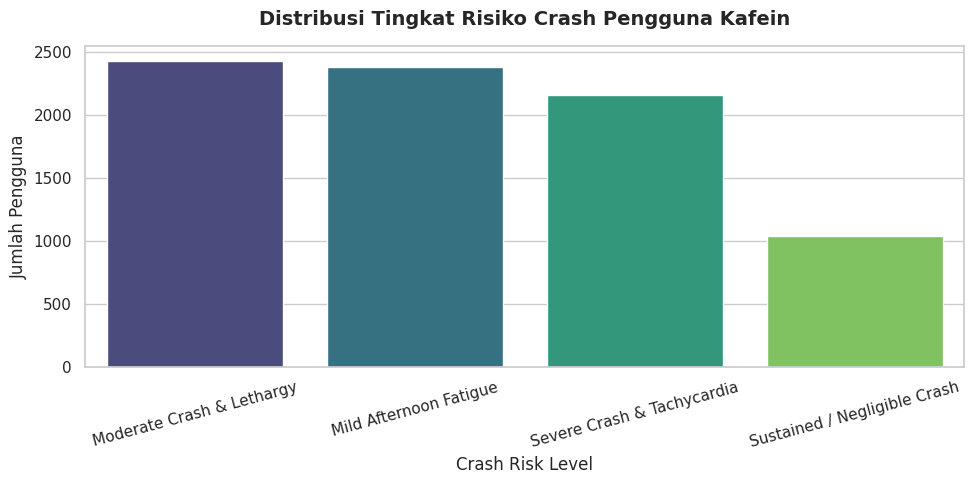

In [19]:
sns.set_theme(style="whitegrid")

# 1. Distribusi Variabel Target (Crash Risk Level)
plt.figure(figsize=(10, 5))
ax = sns.countplot(data=df, x='crash_risk_level', order=df['crash_risk_level'].value_counts().index, palette='viridis')
plt.title('Distribusi Tingkat Risiko Crash Pengguna Kafein', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Crash Risk Level', fontsize=12)
plt.ylabel('Jumlah Pengguna', fontsize=12)
plt.xticks(rotation=15)
plt.tight_layout()
warnings.filterwarnings('ignore')
plt.show()



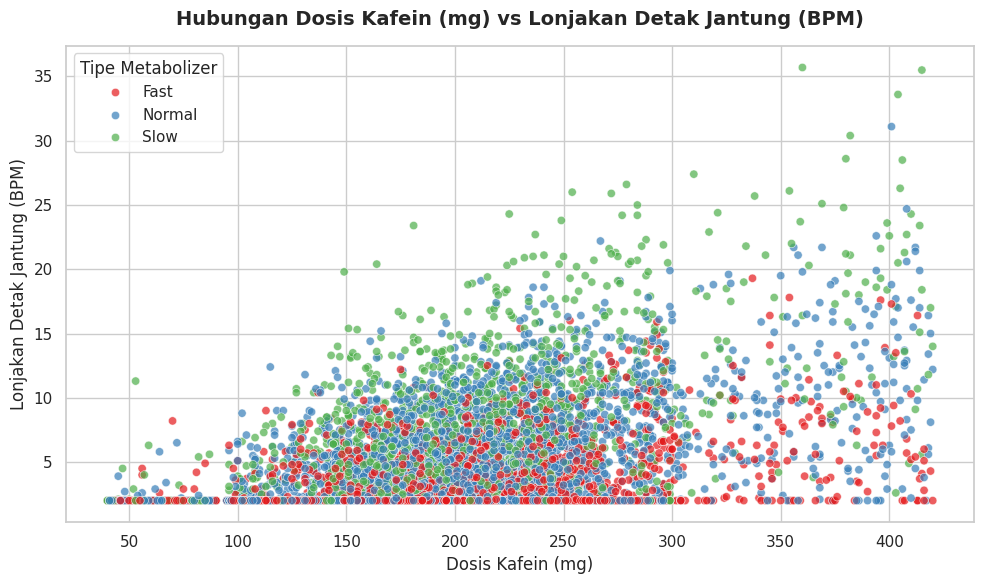

In [20]:
# 2. Hubungan Dosis Kafein vs Lonjakan Detak Jantung
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='caffeine_mg', y='heart_rate_spike_bpm', hue='cyp1a2_metabolizer_type', alpha=0.7, palette='Set1')
plt.title('Hubungan Dosis Kafein (mg) vs Lonjakan Detak Jantung (BPM)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Dosis Kafein (mg)', fontsize=12)
plt.ylabel('Lonjakan Detak Jantung (BPM)', fontsize=12)
plt.legend(title='Tipe Metabolizer')
plt.tight_layout()
warnings.filterwarnings('ignore')
plt.show()

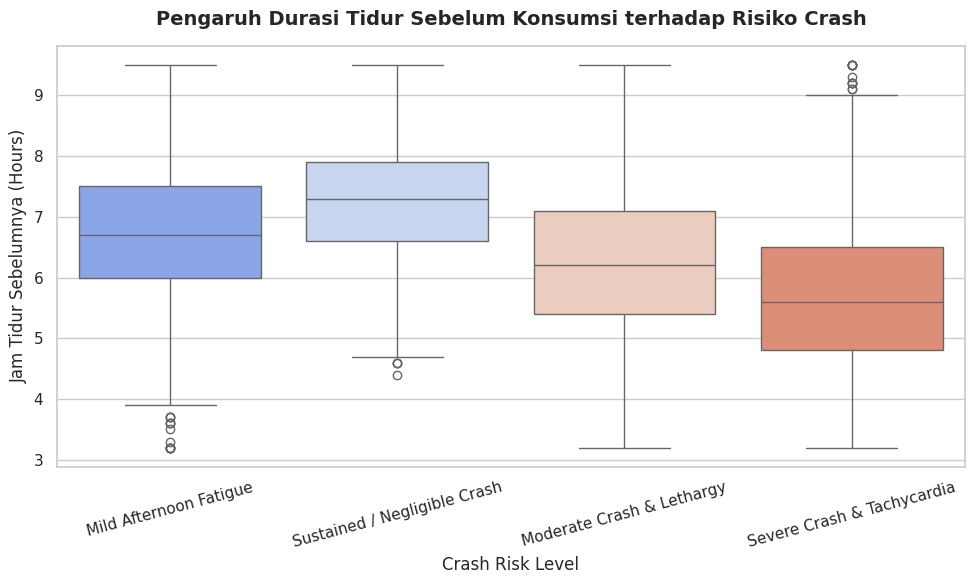

In [21]:
# 3. Pengaruh Durasi Tidur terhadap Risiko Crash
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='crash_risk_level', y='prior_sleep_hours', palette='coolwarm')
plt.title('Pengaruh Durasi Tidur Sebelum Konsumsi terhadap Risiko Crash', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Crash Risk Level', fontsize=12)
plt.ylabel('Jam Tidur Sebelumnya (Hours)', fontsize=12)
plt.xticks(rotation=15)
plt.tight_layout()
warnings.filterwarnings('ignore')
plt.show()

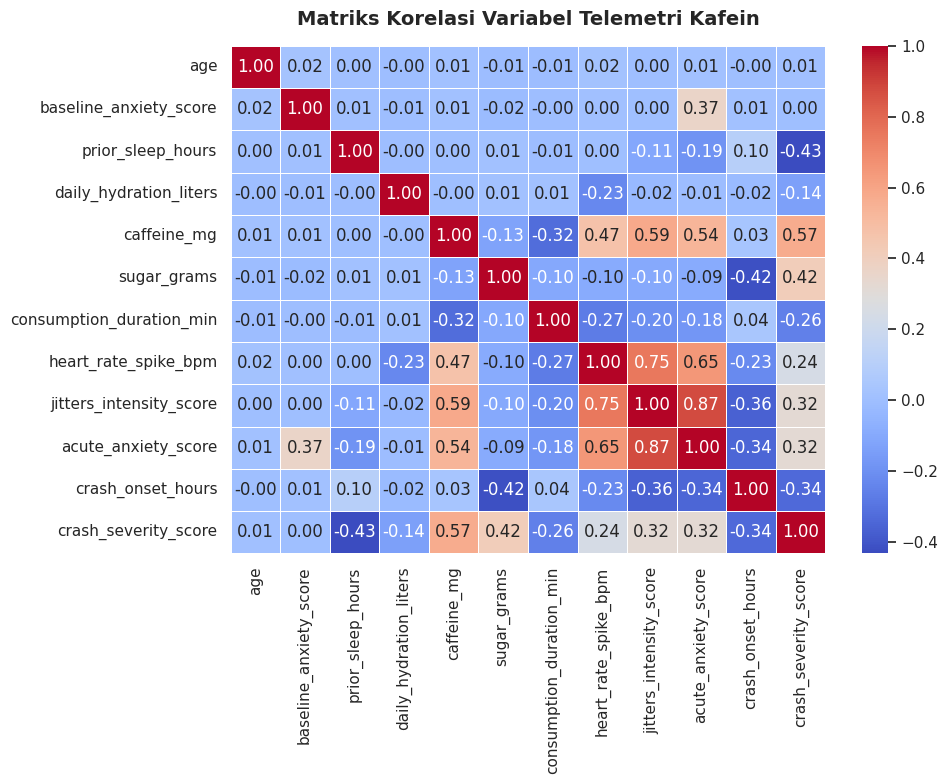

In [22]:
# 4. Matriks Korelasi Antar Variabel Numerik
plt.figure(figsize=(10, 8))
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Matriks Korelasi Variabel Telemetri Kafein', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
warnings.filterwarnings('ignore')
plt.show()